# Jalon M1 — avenue de Versailles, Sèvres, quai d'Orsay

Période : 1er mars 2026 au 31 août 2026. Source : comptages routiers permanents de la Ville de Paris.

1. Télécharger les trois axes avec `python download_data.py`.
2. Lire le CSV par paquets, avec un type par colonne.
3. Regarder la taille du tableau, les types et les trous.
4. Trois graphiques simples (matplotlib), chacun suivi d'une phrase tirée des chiffres.

`t_1h` est en UTC et marque la fin de l'heure. Pour lire une journée, on passe en heure de Paris.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas import CategoricalDtype

%matplotlib inline

dossier = Path.cwd()
if not (dossier / "data" / "raw" / "comptages.csv").exists():
    dossier = dossier.parent
fichier = dossier / "data" / "raw" / "comptages.csv"
figures = dossier / "figures"
figures.mkdir(parents=True, exist_ok=True)

axes = ["Av_de_Versailles", "Sevres", "Quai_d'Orsay"]
noms = {
    "Av_de_Versailles": "Avenue de Versailles",
    "Sevres": "Sèvres",
    "Quai_d'Orsay": "Quai d'Orsay",
}
ordre_noms = [noms[axe] for axe in axes]
ordre_etats = ["Fluide", "Pré-saturé", "Saturé", "Bloqué", "Inconnu"]

types = {
    "iu_ac": "Int64",
    "libelle": CategoricalDtype(axes),
    "q": "float64",
    "k": "float64",
    "etat_trafic": CategoricalDtype(ordre_etats, ordered=True),
    "iu_nd_amont": "Int64",
    "libelle_nd_amont": "string",
    "iu_nd_aval": "Int64",
    "libelle_nd_aval": "string",
    "etat_barre": CategoricalDtype(["Inconnu", "Ouvert", "Barré", "Invalide"]),
}

# Une couleur par axe (identité) et une couleur par état de trafic (du fluide
# au bloqué), réutilisées sur les trois graphiques pour rester cohérent d'un
# graphique à l'autre.
couleur_axe = {
    "Avenue de Versailles": "#2a78d6",  # bleu
    "Sèvres": "#eb6834",                # orange
    "Quai d'Orsay": "#1baf7a",          # vert d'eau
}
couleur_etat = {
    "Fluide": "#0ca30c",       # vert : ça circule
    "Pré-saturé": "#fab219",   # jaune : ça commence à ralentir
    "Saturé": "#ec835a",       # orange foncé : ça bloque
    "Bloqué": "#d03b3b",       # rouge : à l'arrêt
    "Inconnu": "#c3c2b7",      # gris : pas de mesure, pas un jugement sur le trafic
}

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": "#e1e0d9",
    "axes.labelcolor": "#52514e",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "font.size": 11,
})


## Chargement par paquets

Le fichier est en UTF-8 (avec un BOM) et les colonnes sont séparées par des points-virgules. Les catégories sont données dès la lecture, pour que les paquets se concatènent sans mélange de codes.

In [2]:
paquets = []
lecture = pd.read_csv(
    fichier,
    sep=";",
    encoding="utf-8-sig",
    dtype=types,
    parse_dates=["t_1h"],
    chunksize=50_000,
)
for numero, paquet in enumerate(lecture, start=1):
    print(f"paquet {numero} : {len(paquet)} lignes")
    paquets.append(paquet)

df = pd.concat(paquets, ignore_index=True)

if set(df["libelle"].dropna().astype(str)) != set(axes):
    raise ValueError("Le fichier ne contient pas exactement les trois axes prévus.")

df.head(3)

paquet 1 : 50000 lignes
paquet 2 : 50000 lignes


paquet 3 : 50000 lignes
paquet 4 : 28924 lignes


,iu_ac,libelle,t_1h,q,k,etat_trafic,iu_nd_amont,libelle_nd_amont,iu_nd_aval,libelle_nd_aval,etat_barre
0,5592,Sevres,2026-08-31 23:00:00+00:00,70.0,1.03500,Fluide,2939,Sevres-Bac,202,Sevres-Babylone,Ouvert
1,5593,Sevres,2026-08-31 23:00:00+00:00,288.0,0.54500,Fluide,202,Sevres-Babylone,2939,Sevres-Bac,Ouvert
2,4398,Quai_d'Orsay,2026-08-31 23:00:00+00:00,148.0,2.08611,Fluide,2349,Pl_de_Finlande,3522,Quai_d'Orsay-face_57-59,Ouvert


## Dimensions, types, valeurs manquantes

In [3]:
print(f"{df.shape[0]} lignes, {df.shape[1]} colonnes")
print(f"Du {df['t_1h'].min()} au {df['t_1h'].max()} (UTC)")
print(df.groupby("libelle", observed=True)["iu_ac"].nunique().rename("arcs"))

bilan = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "manquants": df.isna().sum(),
    "part": (df.isna().mean() * 100).round(1),
})
bilan

178924 lignes, 11 colonnes
Du 2026-03-01 00:00:00+00:00 au 2026-08-31 23:00:00+00:00 (UTC)
libelle
Av_de_Versailles    16
Sevres              10
Quai_d'Orsay        15
Name: arcs, dtype: int64


,type,manquants,part
iu_ac,Int64,0,0.0
libelle,category,0,0.0
t_1h,"datetime64[us, UTC]",0,0.0
q,float64,22826,12.8
k,float64,31168,17.4
etat_trafic,category,0,0.0
iu_nd_amont,Int64,0,0.0
libelle_nd_amont,string,0,0.0
iu_nd_aval,Int64,0,0.0
libelle_nd_aval,string,0,0.0


## Débit et occupation : qui est le mieux mesuré ?

Pour chaque axe, deux barres côte à côte : la part d'heures où le **débit** `q` est connu, et la part d'heures où le **taux d'occupation** `k` est connu. Comparer deux barres pleines côte à côte se lit plus vite que comparer une barre à un repère : c'est pour ça que les deux mesures sont des barres, pas une barre et un tiret.


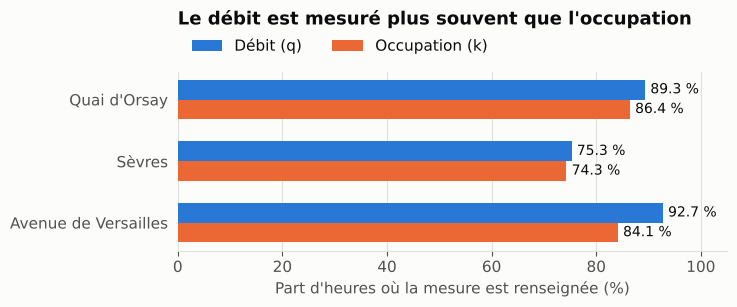

In [4]:
completude = (
    df.assign(axe=df["libelle"].astype(str).map(noms))
    .groupby("axe", observed=True)
    .agg(
        debit_renseigne=("q", lambda s: 100 * s.notna().mean()),
        occupation_renseignee=("k", lambda s: 100 * s.notna().mean()),
    )
    .reindex(ordre_noms)
)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(ordre_noms))
h = 0.32

ax.barh(y + h / 2, completude["debit_renseigne"], height=h, color="#2a78d6", label="Débit (q)")
ax.barh(y - h / 2, completude["occupation_renseignee"], height=h, color="#eb6834", label="Occupation (k)")

# Le chiffre écrit au bout de chaque barre évite d'avoir à lire l'axe des x.
for yi, debit, occ in zip(y, completude["debit_renseigne"], completude["occupation_renseignee"]):
    ax.text(debit + 1, yi + h / 2, f"{debit:.1f} %", va="center", fontsize=10)
    ax.text(occ + 1, yi - h / 2, f"{occ:.1f} %", va="center", fontsize=10)

ax.set_yticks(y, ordre_noms)
ax.set_xlim(0, 105)
ax.set_xlabel("Part d'heures où la mesure est renseignée (%)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)
ax.xaxis.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Le débit est mesuré plus souvent que l'occupation", loc="left", fontsize=13, fontweight="bold", pad=34)
ax.legend(loc="lower left", frameon=False, ncols=2, bbox_to_anchor=(0, 1.02))

fig.tight_layout()
fig.savefig(figures / "01_barres_tirets.png", dpi=150, bbox_inches="tight")
plt.show()


### Interprétation

**Ce que montre ce graphique.** Pour chaque axe, la barre bleue est la part d'heures où le débit est connu, la barre orange la part d'heures où l'occupation est connue. Les deux partent du même point à gauche : plus elles ont une longueur proche, plus les deux mesures sont renseignées aussi souvent l'une que l'autre.

**En chiffres.** Sur les trois axes, le débit est renseigné plus souvent que l'occupation. Avenue de Versailles : 92,7 % de débit contre 84,1 % d'occupation, l'écart le plus net des trois (8,6 points). Quai d'Orsay : 89,3 % contre 86,4 %. Sèvres : 75,3 % contre 74,3 %, l'écart le plus faible — mais aussi l'axe le moins bien mesuré dans l'ensemble, sur les deux variables à la fois. En pratique, on peut souvent compter des voitures sans connaître le niveau d'encombrement.


## Composition du trafic par état

Pour chaque axe, une seule barre empilée à 100 % : chaque segment est la part des heures passées dans un état de trafic donné, du vert (fluide) au rouge (bloqué), avec le gris pour les heures sans mesure. Une barre par axe, lue de gauche à droite, se compare d'un coup d'œil — pas besoin de parcourir plusieurs panneaux séparés.


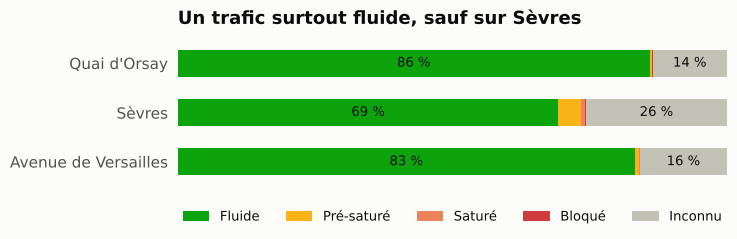

In [5]:
etats = (
    df.assign(axe=df["libelle"].astype(str).map(noms))
    .groupby(["axe", "etat_trafic"], observed=True)
    .size()
    .rename("heures")
    .reset_index()
)
etats["part"] = etats.groupby("axe")["heures"].transform(lambda s: 100 * s / s.sum())
composition = (
    etats.pivot(index="axe", columns="etat_trafic", values="part")
    .reindex(ordre_noms)[ordre_etats]
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
y = np.arange(len(composition))
gauche = np.zeros(len(composition))

for etat in ordre_etats:
    valeurs = composition[etat].to_numpy()
    ax.barh(y, valeurs, left=gauche, height=0.55, color=couleur_etat[etat], label=etat)
    # Pas d'étiquette sur les segments trop fins (moins de 5 %) : le chiffre
    # ne tiendrait pas et nuirait à la lisibilité plus qu'il n'aiderait.
    for yi, v, g in zip(y, valeurs, gauche):
        if v >= 5:
            couleur_texte = "white" if etat in ("Saturé", "Bloqué") else "#0b0b0b"
            ax.text(g + v / 2, yi, f"{v:.0f} %", va="center", ha="center", fontsize=9.5, color=couleur_texte)
    gauche += valeurs

ax.set_yticks(y, composition.index)
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(left=False)
ax.set_title("Un trafic surtout fluide, sauf sur Sèvres", loc="left", fontsize=13, fontweight="bold", pad=14)
ax.legend(loc="upper center", frameon=False, ncols=5, bbox_to_anchor=(0.5, -0.12), fontsize=9.5)

fig.tight_layout()
fig.savefig(figures / "02_barres_etats.png", dpi=150, bbox_inches="tight")
plt.show()


### Interprétation

**Ce que montre ce graphique.** Chaque barre est un axe, chaque segment coloré une part du temps : vert pour fluide, jaune puis orange pour pré-saturé et saturé, rouge pour bloqué, gris pour inconnu. Plus la barre est verte, mieux l'axe circule ; plus elle est grise, moins elle est mesurée.

**En chiffres.** Le quai d'Orsay et l'avenue de Versailles sont fluides respectivement 86,0 % et 83,2 % du temps, avec un segment gris étroit (13,6 % et 15,9 %). Sèvres descend à 69,3 % de fluidité, avec un segment gris net (25,7 % d'heures « Inconnu ») et les seuls segments jaune et orange vraiment visibles (4,0 % de pré-saturation, 0,8 % de saturation). Le gris ne veut pas dire embouteillage : il suit surtout l'absence de taux d'occupation. Sèvres apparaît donc à la fois un peu plus contrainte et moins bien mesurée que les deux autres axes.


## Profil horaire du débit

Trois courbes, une par axe, le débit médian à chaque heure de la journée (heure de Paris). Le nom de chaque axe et son maximum sont écrits directement à côté de sa courbe plutôt que dans une légende séparée : pas d'aller-retour entre le graphique et une légende pour savoir quelle couleur correspond à quel axe.


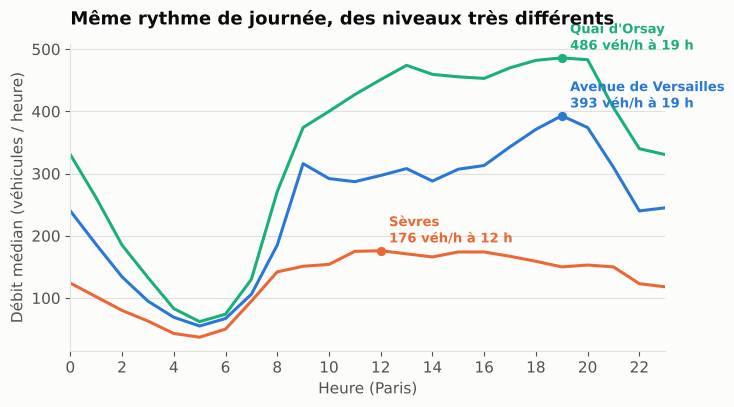

In [6]:
par_heure = (
    df.assign(heure=df["t_1h"].dt.tz_convert("Europe/Paris").dt.hour)
    .groupby(["heure", "libelle"], observed=True)["q"]
    .median()
    .unstack("libelle")
)
par_heure.columns = [noms[str(col)] for col in par_heure.columns]
par_heure = par_heure[ordre_noms]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for axe_nom in ordre_noms:
    couleur = couleur_axe[axe_nom]
    ax.plot(par_heure.index, par_heure[axe_nom], color=couleur, linewidth=2.2)

    heure_max = par_heure[axe_nom].idxmax()
    debit_max = par_heure[axe_nom].max()
    ax.scatter([heure_max], [debit_max], color=couleur, s=32, zorder=5)
    ax.annotate(
        f"{axe_nom}\n{debit_max:.0f} véh/h à {heure_max} h",
        xy=(heure_max, debit_max), xytext=(6, 6), textcoords="offset points",
        fontsize=9.5, color=couleur, fontweight="bold",
    )

ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Heure (Paris)")
ax.set_ylabel("Débit médian (véhicules / heure)")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Même rythme de journée, des niveaux très différents", loc="left", fontsize=13, fontweight="bold", pad=14)

fig.tight_layout()
fig.savefig(figures / "03_debit_horaire.png", dpi=150, bbox_inches="tight")
plt.show()


### Interprétation

**Ce que montre ce graphique.** Les trois courbes suivent le même rythme de journée : nuit calme, montée le matin, plateau dans la journée, puis redescente le soir. Ce qui change, c'est la hauteur. Le quai d'Orsay (vert) est clairement l'axe le plus fréquenté ; l'avenue de Versailles (bleu) est intermédiaire ; Sèvres (orange) reste bas et assez plat une fois la journée commencée.

**En chiffres.** Le creux tombe à 5 h pour les trois axes. La pointe est à 19 h au quai d'Orsay (486 véh/h) et à l'avenue de Versailles (393 véh/h), contre 12 h seulement sur Sèvres (176 véh/h). Autrement dit, le quai d'Orsay et l'avenue de Versailles portent une vraie pointe de fin d'après-midi, alors que Sèvres ne montre pas le même « coup de frein » du soir : son trafic reste modéré toute la journée. Le quai d'Orsay reste au-dessus des deux autres axes à chaque heure de la journée : ce n'est pas seulement une pointe du soir plus forte, c'est un niveau de base plus élevé.
